In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [ ]:
path="/content/drive/MyDrive/Demo/ last_genetic_disorders_modified_no_disorder.csv"
data=pd.read_excel(path)

In [ ]:
data

,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Disorder Subclass
0,PID0x6418,2.0,Yes,No,Yes,No,4.760603,Richard,NaN,Larre,...,NaN,NaN,9.857562,NaN,1.0,1.0,1.0,1.0,1.0,non diabetes
1,PID0x25d5,4.0,Yes,Yes,No,No,4.910669,Mike,NaN,Brycen,...,NaN,Multiple,5.522560,normal,1.0,NaN,1.0,1.0,0.0,non diabetes
2,PID0x4a82,6.0,Yes,No,No,No,4.893297,Kimberly,NaN,Nashon,...,4.0,Singular,NaN,normal,0.0,1.0,1.0,1.0,1.0,diabetes
3,PID0x4ac8,12.0,Yes,No,Yes,No,4.705280,Jeffery,Hoelscher,Aayaan,...,1.0,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,non diabetes
4,PID0x1bf7,11.0,Yes,No,NaN,Yes,4.720703,Johanna,Stutzman,Suave,...,4.0,Multiple,4.098210,NaN,0.0,0.0,0.0,0.0,NaN,non diabetes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21006,PID0x26c,11.0,No,Yes,Yes,No,5.090495,Betty,NaN,Letwan,...,NaN,Multiple,NaN,normal,1.0,NaN,0.0,0.0,0.0,non diabetes
21007,PID0xa01,NaN,No,No,No,Yes,5.214750,Beth,NaN,Trayvion,...,3.0,Singular,7.086312,slightly abnormal,1.0,NaN,1.0,0.0,1.0,non diabetes
21008,PID0x15,5.0,Yes,No,Yes,Yes,5.084831,Craig,Frascone,Shivaan,...,0.0,Multiple,7.924746,NaN,1.0,0.0,0.0,1.0,1.0,non diabetes
21009,PID0x8d32,1.0,Yes,No,No,Yes,5.224828,Francisco,Owen,Dyer,...,1.0,Multiple,12.000000,inconclusive,0.0,1.0,1.0,1.0,0.0,non diabetes


In [ ]:

# =======================================================
# 1️⃣ Load Dataset
# =======================================================
data.columns = data.columns.str.strip()
print("📊 Dataset Loaded Successfully!")
print("Shape:", data.shape, "\n")

📊 Dataset Loaded Successfully!
Shape: (21011, 44) 



In [ ]:
# =======================================================
# 2️⃣ Drop Unnecessary Columns
# =======================================================
cols_to_drop = ['Patient Id', 'Patient First Name', 'Family Name',
                "Father's name", 'Institute Name', 'Location of Institute']
data.drop(columns=cols_to_drop, inplace=True, errors='ignore')

In [ ]:
# =======================================================
# 3️⃣ Handle Missing Values
# =======================================================
num_cols = data.select_dtypes(include=['float64', 'int64']).columns
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

cat_cols = data.select_dtypes(include=['object']).columns
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

In [ ]:
data.head()

,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Disorder Subclass
0,2.0,Yes,No,Yes,No,4.760603,35.0,42.0,Alive,Normal (30-60),...,2.0,Singular,9.857562,slightly abnormal,1.0,1.0,1.0,1.0,1.0,non diabetes
1,4.0,Yes,Yes,No,No,4.910669,35.0,23.0,Deceased,Tachypnea,...,2.0,Multiple,5.522560,normal,1.0,1.0,1.0,1.0,0.0,non diabetes
2,6.0,Yes,No,No,No,4.893297,41.0,22.0,Alive,Normal (30-60),...,4.0,Singular,7.473071,normal,0.0,1.0,1.0,1.0,1.0,diabetes
3,12.0,Yes,No,Yes,No,4.705280,21.0,42.0,Deceased,Tachypnea,...,1.0,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,non diabetes
4,11.0,Yes,No,Yes,Yes,4.720703,32.0,42.0,Alive,Tachypnea,...,4.0,Multiple,4.098210,slightly abnormal,0.0,0.0,0.0,0.0,0.0,non diabetes


In [ ]:
data.tail(10)

,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Disorder Subclass
21001,7.0,No,No,Yes,Yes,5.056768,35.0,32.0,Alive,Normal (30-60),...,2.0,Singular,6.267448,slightly abnormal,1.0,1.0,1.0,1.0,1.0,diabetes
21002,5.0,Yes,Yes,Yes,Yes,4.966503,34.0,44.0,Alive,Tachypnea,...,0.0,Singular,7.473071,normal,1.0,0.0,0.0,0.0,0.0,non diabetes
21003,5.0,No,Yes,Yes,No,5.129636,35.0,42.0,Alive,Normal (30-60),...,2.0,Multiple,7.177497,slightly abnormal,1.0,1.0,0.0,1.0,0.0,non diabetes
21004,6.0,No,No,No,No,4.946398,34.0,34.0,Deceased,Normal (30-60),...,3.0,Singular,7.473071,normal,0.0,1.0,0.0,1.0,1.0,non diabetes
21005,2.0,Yes,No,Yes,No,5.144151,19.0,42.0,Alive,Tachypnea,...,4.0,Singular,9.863374,slightly abnormal,1.0,0.0,1.0,0.0,0.0,non diabetes
21006,11.0,No,Yes,Yes,No,5.090495,46.0,42.0,Alive,Normal (30-60),...,2.0,Multiple,7.473071,normal,1.0,1.0,0.0,0.0,0.0,non diabetes
21007,7.0,No,No,No,Yes,5.214750,35.0,38.0,Alive,Tachypnea,...,3.0,Singular,7.086312,slightly abnormal,1.0,1.0,1.0,0.0,1.0,non diabetes
21008,5.0,Yes,No,Yes,Yes,5.084831,28.0,28.0,Alive,Normal (30-60),...,0.0,Multiple,7.924746,slightly abnormal,1.0,0.0,0.0,1.0,1.0,non diabetes
21009,1.0,Yes,No,No,Yes,5.224828,33.0,24.0,Deceased,Tachypnea,...,1.0,Multiple,12.000000,inconclusive,0.0,1.0,1.0,1.0,0.0,non diabetes
21010,13.0,No,Yes,Yes,No,5.137942,42.0,21.0,Alive,Tachypnea,...,1.0,Multiple,6.751866,inconclusive,1.0,0.0,1.0,0.0,0.0,non diabetes


In [ ]:
# =======================================================
# 4️⃣ Encode Categorical Columns
# =======================================================
label_enc = LabelEncoder()
for col in cat_cols:
    data[col] = label_enc.fit_transform(data[col])

In [ ]:
# =======================================================
# 5️⃣ Identify Target Column
# =======================================================
target_col = None
for col in data.columns:
    if 'disorder' in col.lower() or 'subclass' in col.lower():
        target_col = col
        break

if target_col is None:
    raise ValueError("❌ Target column not found!")

X = data.drop(columns=[target_col])
y = data[target_col]

In [ ]:
# =======================================================
# 6️⃣ Scale Numeric Features
# =======================================================
scaler = StandardScaler()
num_cols_for_scaling = X.select_dtypes(include=['float64', 'int64']).columns
X_scaled = X.copy()
X_scaled[num_cols_for_scaling] = scaler.fit_transform(X[num_cols_for_scaling])

# =======================================================
# 7️⃣ Train-Test Split
# =======================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print("✅ Train-Test Split Done!")
print("Training:", X_train.shape, "Testing:", X_test.shape, "\n")

✅ Train-Test Split Done!
Training: (16808, 37) Testing: (4203, 37) 



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:43:53] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



📌 ACCURACY BEFORE SMOTE
Training Accuracy (Before SMOTE): 99.94%
Testing Accuracy  (Before SMOTE): 91.53%



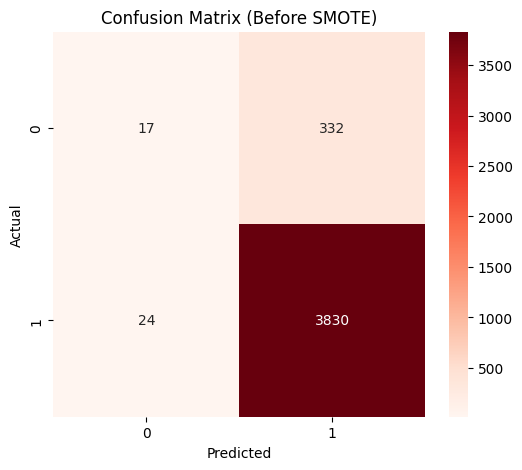

In [ ]:
# =======================================================
# 8️⃣ BASELINE MODEL (Before SMOTE)
# =======================================================
xgb_before = XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    random_state=42, eval_metric='logloss', use_label_encoder=False
)
xgb_before.fit(X_train, y_train)

train_pred_before = xgb_before.predict(X_train)
test_pred_before = xgb_before.predict(X_test)

train_acc_before = accuracy_score(y_train, train_pred_before)
test_acc_before = accuracy_score(y_test, test_pred_before)

print("\n==============================")
print("📌 ACCURACY BEFORE SMOTE")
print("==============================")
print(f"Training Accuracy (Before SMOTE): {train_acc_before*100:.2f}%")
print(f"Testing Accuracy  (Before SMOTE): {test_acc_before*100:.2f}%\n")

# CONFUSION MATRIX (BEFORE SMOTE)
cm_before = confusion_matrix(y_test, test_pred_before)
plt.figure(figsize=(6,5))
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Reds')
plt.title("Confusion Matrix (Before SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# =======================================================
# 9️⃣ SMOTE on TRAINING SET
# =======================================================
print("🔄 Applying SMOTE on TRAINING set...")
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
print(pd.Series(y_train_res).value_counts(), "\n")

🔄 Applying SMOTE on TRAINING set...
Disorder Subclass
1    15414
0    15414
Name: count, dtype: int64 



X_train_res, y_train_res X_test_res, y_test_res

In [ ]:

# =======================================================
# 🔟 SMOTE on TEST SET (Synthetic - Experimental)
# =======================================================
print("🔄 Applying SMOTE on TEST set...")
X_test_res, y_test_res = sm.fit_resample(X_test, y_test)
print(pd.Series(y_test_res).value_counts(), "\n")

🔄 Applying SMOTE on TEST set...
Disorder Subclass
1    3854
0    3854
Name: count, dtype: int64 



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:43:55] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


📌 ACCURACY AFTER SMOTE
Training Accuracy (After SMOTE): 99.54%
Testing Accuracy  (SMOTE Test): 95.17%



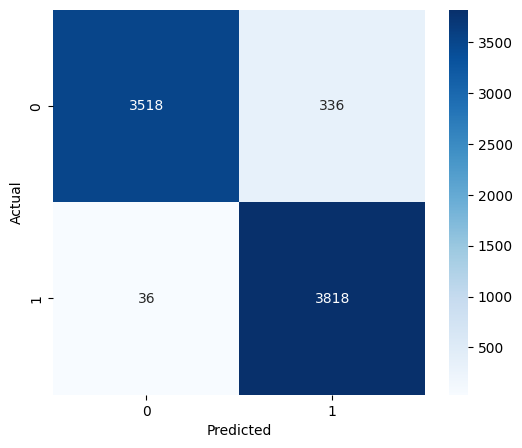

📊 PRECISION / RECALL / F1-SCORE TABLE
                    Dataset  Precision    Recall  F1-Score
0  Real Test (Before SMOTE)   0.920231  0.993773  0.955589
1  SMOTE Test (After SMOTE)   0.919114  0.990659  0.953546 


🎯 FULL PIPELINE + ACCURACIES + CONFUSION MATRICES COMPLETED SUCCESSFULLY!


In [ ]:

# =======================================================
# 1️⃣1️⃣ Train XGBoost AFTER SMOTE
# =======================================================
scale_pos_weight = len(y_train_res[y_train_res == 0]) / len(y_train_res[y_train_res == 1])

xgb_after = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)

xgb_after.fit(X_train_res, y_train_res)

train_pred_after = xgb_after.predict(X_train_res)
test_pred_after = xgb_after.predict(X_test_res)

train_acc_after = accuracy_score(y_train_res, train_pred_after)
test_acc_after = accuracy_score(y_test_res, test_pred_after)

print("==============================")
print("📌 ACCURACY AFTER SMOTE")
print("==============================")
print(f"Training Accuracy (After SMOTE): {train_acc_after*100:.2f}%")
print(f"Testing Accuracy  (SMOTE Test): {test_acc_after*100:.2f}%\n")

# CONFUSION MATRIX (AFTER SMOTE)
cm_after = confusion_matrix(y_test_res, test_pred_after)
plt.figure(figsize=(6,5))
sns.heatmap(cm_after, annot=True, fmt='d', cmap='Blues')
#plt.title("Confusion Matrix (After SMOTE - Synthetic Test)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# =======================================================
# 1️⃣2️⃣ Precision, Recall, F1 TABLE
# =======================================================

prec_real, rec_real, f1_real, _ = precision_recall_fscore_support(
    y_test, test_pred_before, average='binary'
)

prec_smt, rec_smt, f1_smt, _ = precision_recall_fscore_support(
    y_test_res, test_pred_after, average='binary'
)

metrics_table = pd.DataFrame({
    "Dataset": ["Real Test (Before SMOTE)", "SMOTE Test (After SMOTE)"],
    "Precision": [prec_real, prec_smt],
    "Recall": [rec_real, rec_smt],
    "F1-Score": [f1_real, f1_smt]
})

print("📊 PRECISION / RECALL / F1-SCORE TABLE")
print(metrics_table, "\n")

# =======================================================
# 🎯 All Done
# =======================================================
print("\n🎯 FULL PIPELINE + ACCURACIES + CONFUSION MATRICES COMPLETED SUCCESSFULLY!")

In [ ]:
# =======================================================
# 1️⃣4️⃣ FINAL TESTING PREDICTION OUTPUT IN YOUR FORMAT
# =======================================================

label_mapping = {
    0: 'no genetic disorder (non diabetes)',
    1: 'multifactorial genetic disorder – diabetes'
}

# Convert test labels to text
actual_text = [label_mapping[val] for val in y_test]
predicted_text = [label_mapping[val] for val in test_pred_before]

# Create dataframe exactly as your required output
final_pred_df = pd.DataFrame({
    "Actual_Disorder": actual_text,
    "Predicted_Disorder": predicted_text
}, index=X_test.index)

# Print first 10 (or all if you want)
print("\n==============================")
print("🔮 FINAL TESTING PREDICTIONS (YOUR FORMAT)")
print("==============================\n")

print(final_pred_df.head(10))



🔮 FINAL TESTING PREDICTIONS (YOUR FORMAT)

                                  Actual_Disorder  \
20798  multifactorial genetic disorder – diabetes   
7099   multifactorial genetic disorder – diabetes   
10597  multifactorial genetic disorder – diabetes   
18855  multifactorial genetic disorder – diabetes   
4960   multifactorial genetic disorder – diabetes   
20911  multifactorial genetic disorder – diabetes   
19326  multifactorial genetic disorder – diabetes   
4536   multifactorial genetic disorder – diabetes   
20439          no genetic disorder (non diabetes)   
12796  multifactorial genetic disorder – diabetes   

                               Predicted_Disorder  
20798  multifactorial genetic disorder – diabetes  
7099   multifactorial genetic disorder – diabetes  
10597  multifactorial genetic disorder – diabetes  
18855  multifactorial genetic disorder – diabetes  
4960   multifactorial genetic disorder – diabetes  
20911  multifactorial genetic disorder – diabetes  
19326  m

In [ ]:
X_train

,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,History of anomalies in previous pregnancies,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
19672,-1.190720,0.824421,1.247929,0.799407,-0.876106,0.058723,0.160353,0.003773,1.00635,1.116013,...,0.894580,-0.745958,0.904104,1.791490,-1.439785,0.763146,-1.219225,-1.178777,-0.903582,-0.843535
14815,0.723433,0.824421,-0.801328,-1.250927,-0.876106,-0.169372,-1.267615,0.003773,1.00635,-0.896047,...,0.894580,-0.000071,0.904104,-0.229177,0.297100,0.763146,0.820193,-1.178777,-0.903582,-0.843535
13281,-0.951451,0.824421,-0.801328,0.799407,1.141415,0.266847,0.279350,0.003773,-0.99369,1.116013,...,-1.117842,-1.491844,-1.106068,1.791490,-0.571343,0.763146,-1.219225,-1.178777,1.106706,-0.843535
12263,1.441240,0.824421,-0.801328,0.799407,-0.876106,1.613229,0.636342,1.262232,-0.99369,-0.896047,...,0.894580,0.745816,0.904104,1.554954,-1.439785,0.763146,-1.219225,0.848337,-0.903582,-0.843535
8778,-0.951451,-1.212972,-0.801328,0.799407,1.141415,0.948077,-1.862601,1.082452,-0.99369,-0.896047,...,0.894580,-0.000071,-1.106068,1.598879,0.297100,0.763146,0.820193,-1.178777,-0.903582,-0.843535
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3276,0.484164,-1.212972,1.247929,0.799407,1.141415,-0.760290,0.041355,0.093663,1.00635,-0.896047,...,-1.117842,1.491702,0.904104,-0.004157,-0.571343,-1.310365,0.820193,0.848337,1.106706,-0.843535
15026,0.484164,0.824421,1.247929,0.799407,1.141415,1.025586,-1.624607,0.183553,1.00635,-0.896047,...,0.894580,-0.000071,0.904104,-0.690653,0.297100,0.763146,-1.219225,-1.178777,-0.903582,1.185488
11096,1.441240,0.824421,1.247929,-1.250927,1.141415,-0.153671,0.041355,0.003773,-0.99369,-0.896047,...,0.894580,-0.000071,0.904104,-0.004157,-0.571343,-1.310365,0.820193,-1.178777,-0.903582,-0.843535
9239,0.484164,0.824421,-0.801328,0.799407,1.141415,-1.706388,-0.791626,0.003773,1.00635,-0.896047,...,-1.117842,1.491702,-1.106068,0.858281,-1.439785,0.763146,-1.219225,0.848337,-0.903582,-0.843535


In [ ]:
y_train

,Disorder Subclass
19672,1
14815,1
13281,1
12263,1
8778,1
...,...
3276,0
15026,1
11096,1
9239,1


In [ ]:
X_test

,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,History of anomalies in previous pregnancies,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
20798,-0.712182,0.824421,-0.801328,-1.250927,-0.876106,-2.065133,-0.434634,0.003773,-0.99369,1.116013,...,0.894580,-1.491844,0.904104,0.683844,0.297100,0.763146,0.820193,-1.178777,-0.903582,-0.843535
7099,-1.190720,-1.212972,1.247929,0.799407,-0.876106,-0.709620,0.041355,0.003773,1.00635,1.116013,...,0.894580,0.745816,0.904104,-0.921090,-0.571343,0.763146,-1.219225,0.848337,-0.903582,-0.843535
10597,-0.951451,-1.212972,1.247929,0.799407,-0.876106,1.011694,0.160353,0.183553,1.00635,1.116013,...,0.894580,0.745816,-1.106068,1.542899,1.165542,-1.310365,0.820193,0.848337,-0.903582,-0.843535
18855,0.962702,-1.212972,1.247929,-1.250927,-0.876106,-0.198758,-0.791626,-1.254685,1.00635,1.116013,...,0.894580,-1.491844,-1.106068,-1.778439,-0.571343,-1.310365,0.820193,0.848337,-0.903582,-0.843535
4960,0.244895,0.824421,-0.801328,0.799407,1.141415,-1.134186,-0.434634,0.003773,-0.99369,-0.896047,...,-1.117842,-0.745958,-1.106068,-1.778439,0.297100,-1.310365,-1.219225,-1.178777,1.106706,-0.843535
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15640,0.244895,0.824421,-0.801328,-1.250927,-0.876106,-1.920792,0.041355,-1.973804,-0.99369,1.116013,...,0.894580,-0.745958,-1.106068,-1.673265,-0.571343,0.763146,0.820193,0.848337,1.106706,1.185488
4119,0.962702,0.824421,1.247929,-1.250927,1.141415,0.279975,-1.267615,0.003773,1.00635,-0.896047,...,-1.117842,-0.000071,0.904104,-0.261201,1.165542,0.763146,0.820193,-1.178777,-0.903582,-0.843535
13755,1.441240,0.824421,-0.801328,0.799407,-0.876106,0.393071,1.826315,1.531902,-0.99369,-0.896047,...,-1.117842,-0.000071,-1.106068,-0.220635,1.165542,0.763146,0.820193,0.848337,-0.903582,1.185488
5625,1.680509,0.824421,-0.801328,-1.250927,1.141415,-1.975381,1.350326,0.183553,-0.99369,1.116013,...,0.894580,-0.745958,-1.106068,1.791490,1.165542,0.763146,0.820193,-1.178777,-0.903582,-0.843535


In [ ]:
y_test

,Disorder Subclass
20798,1
7099,1
10597,1
18855,1
4960,1
...,...
15640,0
4119,1
13755,0
5625,1


In [ ]:
X_train_res

,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Mother's age,Father's age,Status,Respiratory Rate (breaths/min),...,History of anomalies in previous pregnancies,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
0,-1.190720,0.824421,1.247929,0.799407,-0.876106,0.058723,0.160353,0.003773,1.00635,1.116013,...,0.894580,-0.745958,0.904104,1.791490,-1.439785,0.763146,-1.219225,-1.178777,-0.903582,-0.843535
1,0.723433,0.824421,-0.801328,-1.250927,-0.876106,-0.169372,-1.267615,0.003773,1.00635,-0.896047,...,0.894580,-0.000071,0.904104,-0.229177,0.297100,0.763146,0.820193,-1.178777,-0.903582,-0.843535
2,-0.951451,0.824421,-0.801328,0.799407,1.141415,0.266847,0.279350,0.003773,-0.99369,1.116013,...,-1.117842,-1.491844,-1.106068,1.791490,-0.571343,0.763146,-1.219225,-1.178777,1.106706,-0.843535
3,1.441240,0.824421,-0.801328,0.799407,-0.876106,1.613229,0.636342,1.262232,-0.99369,-0.896047,...,0.894580,0.745816,0.904104,1.554954,-1.439785,0.763146,-1.219225,0.848337,-0.903582,-0.843535
4,-0.951451,-1.212972,-0.801328,0.799407,1.141415,0.948077,-1.862601,1.082452,-0.99369,-0.896047,...,0.894580,-0.000071,-1.106068,1.598879,0.297100,0.763146,0.820193,-1.178777,-0.903582,-0.843535
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30823,1.274130,0.824421,-0.801328,0.799407,0.984851,1.061806,1.477507,-0.391458,1.00635,1.116013,...,0.894580,-1.491844,0.748110,-1.233794,1.165542,0.763146,0.820193,0.848337,-0.903582,1.185488
30824,-0.364149,-1.212972,1.247929,0.799407,-0.876106,-0.304520,-0.776482,0.149235,1.00635,-0.896047,...,-0.532402,0.528827,-1.106068,-0.368240,-0.571343,-0.707153,0.820193,0.848337,1.106706,1.185488
30825,1.680509,0.824421,-0.801328,-0.810654,-0.876106,-1.764779,1.069247,1.556701,-0.99369,-0.896047,...,0.894580,-0.320403,0.904104,-1.778439,-0.757825,0.763146,0.820193,0.848337,1.106706,1.185488
30826,-1.567530,0.824421,1.247929,0.799407,0.969860,-0.671805,-0.503038,-1.225944,1.00635,0.944922,...,0.894580,-1.428420,-0.935138,-1.694590,1.165542,-1.310365,-1.045808,0.675967,1.106706,1.185488


In [ ]:
y_test_res

,Disorder Subclass
0,1
1,1
2,1
3,1
4,1
...,...
7703,0
7704,0
7705,0
7706,0


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 15414, number of negative: 1394
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002310 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 698
[LightGBM] [Info] Number of data points in the train set: 16808, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.917063 -> initscore=2.403099
[LightGBM] [Info] Start training from score 2.403099

📌 ACCURACY BEFORE SMOTE (LightGBM)
Train: 95.34%
Test : 91.53%



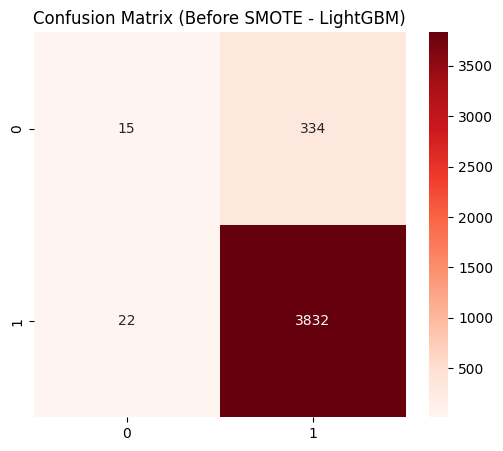

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 15414, number of negative: 15414
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014138 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7905
[LightGBM] [Info] Number of data points in the train set: 30828, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
📌 ACCURACY AFTER SMOTE (LightGBM)
Train: 97.11%
Test : 95.37%


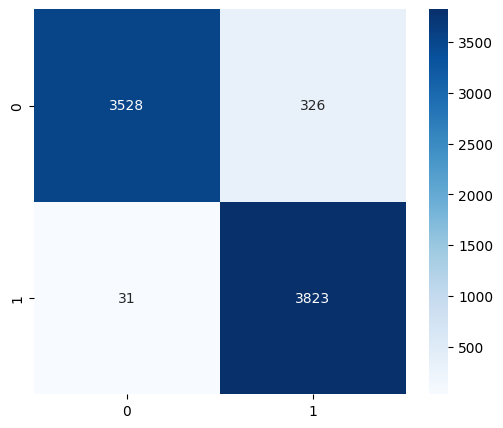

                                  Actual_Disorder  \
20798  multifactorial genetic disorder – diabetes   
7099   multifactorial genetic disorder – diabetes   
10597  multifactorial genetic disorder – diabetes   
18855  multifactorial genetic disorder – diabetes   
4960   multifactorial genetic disorder – diabetes   
20911  multifactorial genetic disorder – diabetes   
19326  multifactorial genetic disorder – diabetes   
4536   multifactorial genetic disorder – diabetes   
20439          no genetic disorder (non diabetes)   
12796  multifactorial genetic disorder – diabetes   

                               Predicted_Disorder  
20798  multifactorial genetic disorder – diabetes  
7099   multifactorial genetic disorder – diabetes  
10597  multifactorial genetic disorder – diabetes  
18855  multifactorial genetic disorder – diabetes  
4960   multifactorial genetic disorder – diabetes  
20911  multifactorial genetic disorder – diabetes  
19326  multifactorial genetic disorder – diabetes  


In [ ]:
# -*- coding: utf-8 -*-
"""Shivani ml - LightGBM Version"""



import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier   # ✅ LightGBM
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

path="/content/drive/MyDrive/Demo/ last_genetic_disorders_modified_no_disorder.csv"
data=pd.read_excel(path)

data.columns = data.columns.str.strip()
cols_to_drop = ['Patient Id', 'Patient First Name', 'Family Name',
                "Father's name", 'Institute Name', 'Location of Institute']
data.drop(columns=cols_to_drop, inplace=True, errors='ignore')

num_cols = data.select_dtypes(include=['float64', 'int64']).columns
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

cat_cols = data.select_dtypes(include=['object']).columns
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

label_enc = LabelEncoder()
for col in cat_cols:
    data[col] = label_enc.fit_transform(data[col])

target_col = None
for col in data.columns:
    if 'disorder' in col.lower() or 'subclass' in col.lower():
        target_col = col
        break

X = data.drop(columns=[target_col])
y = data[target_col]

scaler = StandardScaler()
num_cols_for_scaling = X.select_dtypes(include=['float64', 'int64']).columns
X_scaled = X.copy()
X_scaled[num_cols_for_scaling] = scaler.fit_transform(X[num_cols_for_scaling])

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# =======================================================
# ⭐ BASELINE MODEL — LightGBM (Before SMOTE)
# =======================================================
lgb_before = LGBMClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42
)

lgb_before.fit(X_train, y_train)

train_pred_before = lgb_before.predict(X_train)
test_pred_before = lgb_before.predict(X_test)

train_acc_before = accuracy_score(y_train, train_pred_before)
test_acc_before = accuracy_score(y_test, test_pred_before)

print("\n📌 ACCURACY BEFORE SMOTE (LightGBM)")
print(f"Train: {train_acc_before*100:.2f}%")
print(f"Test : {test_acc_before*100:.2f}%\n")

cm_before = confusion_matrix(y_test, test_pred_before)
plt.figure(figsize=(6,5))
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Reds')
plt.title("Confusion Matrix (Before SMOTE - LightGBM)")
plt.show()

# =======================================================
# ⭐ SMOTE PROCESS (same)
# =======================================================
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
X_test_res, y_test_res = sm.fit_resample(X_test, y_test)

# =======================================================
# ⭐ MODEL AFTER SMOTE — LightGBM
# =======================================================
lgb_after = LGBMClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42
)

lgb_after.fit(X_train_res, y_train_res)

train_pred_after = lgb_after.predict(X_train_res)
test_pred_after = lgb_after.predict(X_test_res)

print("📌 ACCURACY AFTER SMOTE (LightGBM)")
print(f"Train: {accuracy_score(y_train_res, train_pred_after)*100:.2f}%")
print(f"Test : {accuracy_score(y_test_res, test_pred_after)*100:.2f}%")

cm_after = confusion_matrix(y_test_res, test_pred_after)
plt.figure(figsize=(6,5))
sns.heatmap(cm_after, annot=True, fmt='d', cmap='Blues')
#plt.title("Confusion Matrix (After SMOTE - LightGBM)")
plt.show()

# =======================================================
# FINAL PREDICTION TABLE
# =======================================================
label_mapping = {
    0: 'no genetic disorder (non diabetes)',
    1: 'multifactorial genetic disorder – diabetes'
}

actual_text = [label_mapping[val] for val in y_test]
predicted_text = [label_mapping[val] for val in test_pred_before]

final_pred_df = pd.DataFrame({
    "Actual_Disorder": actual_text,
    "Predicted_Disorder": predicted_text
}, index=X_test.index)

print(final_pred_df.head(10))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.1 MB/s eta 0:00:00

📌 ACCURACY BEFORE SMOTE (CatBoost)
Train: 96.79%
Test : 91.65%



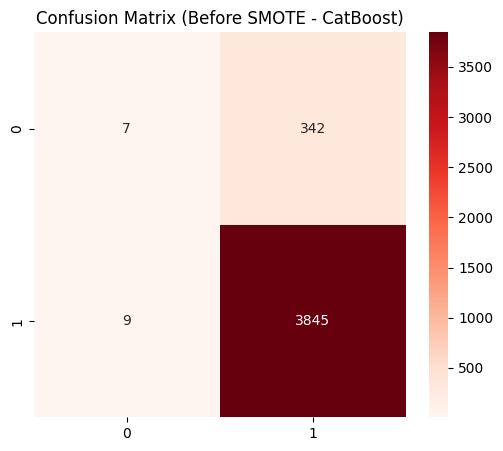

📌 ACCURACY AFTER SMOTE (CatBoost)
Train: 97.53%
Test : 95.33%


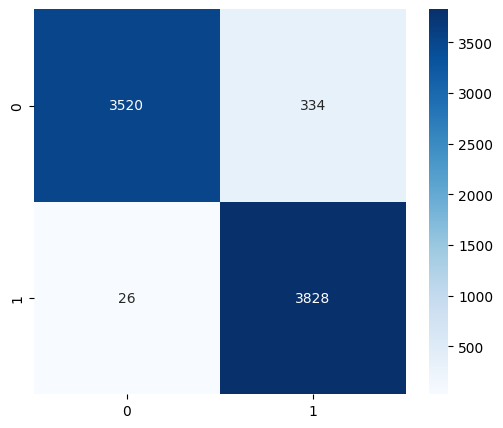

                                  Actual_Disorder  \
20798  multifactorial genetic disorder – diabetes   
7099   multifactorial genetic disorder – diabetes   
10597  multifactorial genetic disorder – diabetes   
18855  multifactorial genetic disorder – diabetes   
4960   multifactorial genetic disorder – diabetes   
20911  multifactorial genetic disorder – diabetes   
19326  multifactorial genetic disorder – diabetes   
4536   multifactorial genetic disorder – diabetes   
20439          no genetic disorder (non diabetes)   
12796  multifactorial genetic disorder – diabetes   

                               Predicted_Disorder  
20798  multifactorial genetic disorder – diabetes  
7099   multifactorial genetic disorder – diabetes  
10597  multifactorial genetic disorder – diabetes  
18855  multifactorial genetic disorder – diabetes  
4960   multifactorial genetic disorder – diabetes  
20911  multifactorial genetic disorder – diabetes  
19326  multifactorial genetic disorder – diabetes  


In [ ]:
# -*- coding: utf-8 -*-
"""Shivani ml - CatBoost Version"""


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from imblearn.over_sampling import SMOTE
!pip install catboost
from catboost import CatBoostClassifier   # ✅ CatBoost
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

path="/content/drive/MyDrive/Demo/ last_genetic_disorders_modified_no_disorder.csv"
data=pd.read_excel(path)

data.columns = data.columns.str.strip()
cols_to_drop = ['Patient Id', 'Patient First Name', 'Family Name',
                "Father's name", 'Institute Name', 'Location of Institute']
data.drop(columns=cols_to_drop, inplace=True, errors='ignore')

num_cols = data.select_dtypes(include=['float64', 'int64']).columns
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

cat_cols = data.select_dtypes(include=['object']).columns
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

label_enc = LabelEncoder()
for col in cat_cols:
    data[col] = label_enc.fit_transform(data[col])

target_col = None
for col in data.columns:
    if 'disorder' in col.lower() or 'subclass' in col.lower():
        target_col = col
        break

X = data.drop(columns=[target_col])
y = data[target_col]

scaler = StandardScaler()
num_cols_for_scaling = X.select_dtypes(include=['float64', 'int64']).columns
X_scaled = X.copy()
X_scaled[num_cols_for_scaling] = scaler.fit_transform(X[num_cols_for_scaling])

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# =======================================================
# ⭐ BASELINE MODEL — CatBoost (Before SMOTE)
# =======================================================
cat_before = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=0
)

cat_before.fit(X_train, y_train)

train_pred_before = cat_before.predict(X_train)
test_pred_before = cat_before.predict(X_test)

train_acc_before = accuracy_score(y_train, train_pred_before)
test_acc_before = accuracy_score(y_test, test_pred_before)

print("\n📌 ACCURACY BEFORE SMOTE (CatBoost)")
print(f"Train: {train_acc_before*100:.2f}%")
print(f"Test : {test_acc_before*100:.2f}%\n")

cm_before = confusion_matrix(y_test, test_pred_before)
plt.figure(figsize=(6,5))
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Reds')
plt.title("Confusion Matrix (Before SMOTE - CatBoost)")
plt.show()

# =======================================================
# ⭐ SMOTE PROCESS
# =======================================================
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
X_test_res, y_test_res = sm.fit_resample(X_test, y_test)

# =======================================================
# ⭐ MODEL AFTER SMOTE — CatBoost
# =======================================================
cat_after = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=0
)

cat_after.fit(X_train_res, y_train_res)

train_pred_after = cat_after.predict(X_train_res)
test_pred_after = cat_after.predict(X_test_res)

print("📌 ACCURACY AFTER SMOTE (CatBoost)")
print(f"Train: {accuracy_score(y_train_res, train_pred_after)*100:.2f}%")
print(f"Test : {accuracy_score(y_test_res, test_pred_after)*100:.2f}%")

cm_after = confusion_matrix(y_test_res, test_pred_after)
plt.figure(figsize=(6,5))
sns.heatmap(cm_after, annot=True, fmt='d', cmap='Blues')
#plt.title("Confusion Matrix (After SMOTE - CatBoost)")
plt.show()

# =======================================================
# FINAL PREDICTION TABLE
# =======================================================
label_mapping = {
    0: 'no genetic disorder (non diabetes)',
    1: 'multifactorial genetic disorder – diabetes'
}

actual_text = [label_mapping[val] for val in y_test]
predicted_text = [label_mapping[val] for val in test_pred_before]

final_pred_df = pd.DataFrame({
    "Actual_Disorder": actual_text,
    "Predicted_Disorder": predicted_text
}, index=X_test.index)

print(final_pred_df.head(10))

In [ ]:
# ============================================================
# 1. IMPORTS
# ============================================================
import pandas as pd
import gradio as gr

# ============================================================
# 2. LOAD DATASET
# ============================================================
df = pd.read_excel("/content/drive/MyDrive/Demo/ last_genetic_disorders_modified_no_disorder.csv")

# ============================================================
# 3. SELECT 21 FEATURES
# ============================================================
features = [
    "Patient Age",
    "Genes in mother's side",
    "Inherited from father",
    "Maternal gene",
    "Paternal gene",
    "Blood cell count (mcL)",
    "White Blood cell count (thousand per microliter)",
    "Blood test result",
    "Mother's age",
    "Father's age",
    "Status",
    "Respiratory Rate (breaths/min)",
    "Birth defects",
    "History of anomalies in previous pregnancies",
    "No. of previous abortion",
    "Symptom 1",
    "Symptom 2",
    "Symptom 3",
    "Symptom 4",
    "Symptom 5",
    "H/O serious maternal illness"
]

target = "Disorder Subclass"

df_small = df[features + [target]].astype(str)

# ============================================================
# 4. NORMALIZATION FUNCTION
# ============================================================
def normalize(v):
    v = str(v).strip().lower()

    if v in ["", "nan", "none", "-", "missing", "not applicable", "not available", "no record"]:
        return "missing"

    if v in ["yes", "y"]:
        return "yes"
    if v in ["no", "n"]:
        return "no"

    # Convert numeric safely
    try:
        return str(float(v))
    except:
        return v

# apply normalizer to entire dataset
df_norm = df_small.copy()
for col in features:
    df_norm[col] = df_norm[col].apply(normalize)

# ============================================================
# 5. PREDICT FUNCTION (ROW MATCHING)
# ============================================================
def predict_diabetes(*inputs):

    user = {features[i]: normalize(inputs[i]) for i in range(len(features))}

    mask = pd.Series([True] * len(df_norm))
    for col in features:
        mask &= (df_norm[col] == user[col])

    match = df_norm[mask]

    if match.empty:
        return "⚠ No exact matching record found in dataset"

    result = match[target].iloc[0].lower()

    return "🟥 Diabetes" if result == "diabetes" else "🟩 Non-Diabetes"

# ============================================================
# 6. GRADIO INTERFACE
# ============================================================
inputs_ui = [gr.Textbox(label=f) for f in features]

app = gr.Interface(
    fn=predict_diabetes,
    inputs=inputs_ui,
    outputs="text",
    title="Genetic Diabetes Checker (21 Features)",
    description="Matches 21 full features from dataset to determine diabetes status."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8ab640e1b48e01884d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
